# Combined Contextual Reranking Evaluation

This notebook evaluates the combined BPR, weather, time,
distance, and budget reranking model through weight sensitivity,
ablation testing, and recommendation evaluation.

In [19]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd().parent if (Path.cwd().parent / 'data').exists() else Path.cwd()
processed = project / 'data' / 'processed'
source = processed / 'combined_contextual_candidates.csv'

if not source.exists():
    raise FileNotFoundError(f'Run Notebook 08 first; expected {source}')

df = pd.read_csv(source, 
    dtype={'user_id':'string','gmap_id':'string'}, 
    low_memory=False)

SCORE_COLS = [
    'bpr_normalized',
    'weather_score',
    'time_score',
    'distance_score',
    'budget_score'
]

required = [
    'user_id',
    'gmap_id',
    'time_availability',
    'distance_miles',
    'price',
    *SCORE_COLS
]

missing = sorted(set(required) - set(df.columns))

if missing: 
    raise ValueError(f'Missing columns: {missing}')

assert not df.duplicated(['user_id','gmap_id']).any(),'Duplicate user–activity candidates'
assert df[SCORE_COLS].notna().all().all(), 'Missing scoring values'
assert np.isfinite(df[SCORE_COLS].to_numpy(dtype=float)).all(), 'Nonfinite scores'
assert df['user_id'].notna().all() and df['gmap_id'].notna().all()

print('Rows:',len(df),'Users:',df.user_id.nunique())
print('Candidates/user:',df.groupby('user_id').size().describe())
display(df[SCORE_COLS].agg(['min','max','mean']))

Rows: 10000 Users: 50
Candidates/user: count     50.0
mean     200.0
std        0.0
min      200.0
25%      200.0
50%      200.0
75%      200.0
max      200.0
dtype: float64


,bpr_normalized,weather_score,time_score,distance_score,budget_score
min,0.000000,0.20000,0.000,-1.000000,-1.0000
max,1.000000,1.00000,1.000,0.996818,1.0000
mean,0.238931,0.92925,0.885,-0.391176,0.7272


In [20]:
RADIUS_MILES = 5.0
MAX_PRICE_LEVEL = 2
WEATHER_THRESHOLD = 0.7
K = 10
COMPONENTS = ['bpr','weather','time','distance','budget']

price_levels = {'$':1, '$$':2, '$$$':3, '$$$$':4}
def price_to_level(value):
    if pd.isna(value): return np.nan
    text = str(value).strip()
    if text in price_levels: return float(price_levels[text])
    try:
        number = float(text)
        return number if number in (1,2,3,4) else np.nan
    except ValueError:
        return np.nan

df['price_level_eval'] = df['price'].map(price_to_level)
df['time_status_eval'] = df['time_availability'].astype('string').str.strip().str.lower()
df['distance_ok'] = pd.to_numeric(df['distance_miles'],errors='coerce').le(RADIUS_MILES)
df['budget_ok'] = df['price_level_eval'].le(MAX_PRICE_LEVEL)
df['weather_ok'] = df['weather_score'].ge(WEATHER_THRESHOLD)
df['time_ok'] = df['time_status_eval'].eq('open').fillna(False)
df['joint_ok'] = df[['distance_ok','budget_ok','weather_ok','time_ok']].all(axis=1)
df['eligible'] = df['time_status_eval'].ne('closed').fillna(True)

print('Price levels:',df['price_level_eval'].value_counts(dropna=False).to_dict())
print('Time statuses:',df['time_status_eval'].value_counts(dropna=False).to_dict())
print('Eligible candidates:',df['eligible'].sum())

# Tie-breaking is deterministic across all configurations.
original_bpr = (df.sort_values(
    ['user_id','bpr_normalized','gmap_id'],
    ascending=[True,False,True])
    .groupby('user_id',sort=False).head(K).copy())

original_sets = original_bpr.groupby('user_id')['gmap_id'].agg(set).to_dict()

def rank_topk(weights, *, filter_closed=True, k=K):
    weights = np.asarray(weights,dtype=float)
    if weights.shape != (5,) or (weights < 0).any() or not np.isclose(weights.sum(),1):
        raise ValueError('Expected five nonnegative weights summing to 1')
    pool = df.loc[df['eligible']] if filter_closed else df
    scored = pool.copy()
    scored['combined_score'] = scored[SCORE_COLS].to_numpy(dtype=float) @ weights
    scored = scored.sort_values(['user_id','combined_score','bpr_normalized','gmap_id'],
                                ascending=[True,False,False,True])
    top = scored.groupby('user_id',sort=False).head(k).copy()
    top['recommendation_rank'] = top.groupby('user_id').cumcount()+1
    return top

bpr_weights = (1.,0.,0.,0.,0.)
filtered_bpr = rank_topk(bpr_weights)

expected_users = set(df["user_id"])

for top in [original_bpr, filtered_bpr]:
    assert set(top["user_id"]) == expected_users, (
        "Missing users in recommendations"
    )

    assert top.groupby("user_id").size().eq(K).all(), (
        "Incorrect number of recommendations per user"
    )

Price levels: {2.0: 4905, 1.0: 2803, nan: 1856, 3.0: 356, 4.0: 80}
Time statuses: {'open': 8503, 'closed': 803, 'unknown': 694}
Eligible candidates: 9197


In [ ]:
def contextual_metrics(top):
    groups = top.groupby('user_id',sort=False)
    overlap = []
    for user, g in groups:
        overlap.append(len(set(g['gmap_id']) & set(original_sets[user])) / K)
        
    return {
        'joint_compatibility':float(top['joint_ok'].mean()),
        'distance_compatibility':float(top['distance_ok'].mean()),
        'budget_compatibility':float(top['budget_ok'].mean()),
        'weather_compatibility':float(top['weather_ok'].mean()),
        'time_compatibility':float(top['time_ok'].mean()),
        'weather_suitability_mean':float(top['weather_score'].mean()),
        'time_suitability_mean':float(top['time_score'].mean()),
        'bpr_overlap':float(np.mean(overlap)),
        'mean_bpr_score':float(top['bpr_normalized'].mean()),
        'users':int(top['user_id'].nunique()),
        'recommendations':int(len(top)),
    }

# Compute unfiltered BPR baseline independently.
original_bpr = original_bpr.sort_values(['user_id','bpr_normalized','gmap_id'],ascending=[True,False,True])
original_bpr['recommendation_rank'] = original_bpr.groupby('user_id').cumcount()+1
baselines = pd.DataFrame([
    {'configuration':'Original BPR (unfiltered)',**contextual_metrics(original_bpr)},
    {'configuration':'Filtered BPR',**contextual_metrics(filtered_bpr)}
])
display(baselines)

,configuration,joint_compatibility,distance_compatibility,budget_compatibility,weather_compatibility,time_compatibility,weather_suitability_mean,time_suitability_mean,bpr_overlap,mean_bpr_score,users,recommendations
0,Original BPR (unfiltered),0.190,0.32,0.698,0.926,0.83,0.903,0.878,1.000,0.761677,50,500
1,Filtered BPR,0.222,0.32,0.710,0.924,0.90,0.902,0.950,0.926,0.751426,50,500


In [22]:
def simplex_weights(units=10):
    for a in range(units+1):
        for b in range(units-a+1):
            for c in range(units-a-b+1):
                for d in range(units-a-b-c+1):
                    e = units-a-b-c-d
                    yield tuple(x/units for x in (a,b,c,d,e))

sensitivity_rows=[]

for weights in simplex_weights(20):
    top = rank_topk(weights)
    sensitivity_rows.append({**dict(zip(COMPONENTS,weights)),**contextual_metrics(top)})
    
sensitivity = pd.DataFrame(sensitivity_rows)
print('Configurations evaluated:',len(sensitivity))
display(sensitivity.sort_values('joint_compatibility',ascending=False).head(10))

Configurations evaluated: 10626


,bpr,weather,time,distance,budget,joint_compatibility,distance_compatibility,budget_compatibility,weather_compatibility,time_compatibility,weather_suitability_mean,time_suitability_mean,bpr_overlap,mean_bpr_score,users,recommendations
2097,0.05,0.05,0.35,0.20,0.35,0.514,0.520,0.994,1.0,1.000,0.9970,1.000,0.322,0.463211,50,500
2363,0.05,0.15,0.05,0.20,0.55,0.514,0.516,1.000,1.0,0.996,1.0000,0.998,0.322,0.463738,50,500
993,0.00,0.25,0.10,0.35,0.30,0.514,0.524,0.992,1.0,0.990,0.9994,0.995,0.258,0.375021,50,500
992,0.00,0.25,0.10,0.30,0.35,0.514,0.522,0.992,1.0,0.992,0.9994,0.996,0.258,0.374822,50,500
991,0.00,0.25,0.10,0.25,0.40,0.514,0.522,0.992,1.0,0.994,1.0000,0.997,0.258,0.374950,50,500
990,0.00,0.25,0.10,0.20,0.45,0.514,0.514,1.000,1.0,0.998,1.0000,0.999,0.262,0.377761,50,500
989,0.00,0.25,0.10,0.15,0.50,0.514,0.514,1.000,1.0,0.998,1.0000,0.999,0.262,0.377761,50,500
988,0.00,0.25,0.10,0.10,0.55,0.514,0.514,1.000,1.0,1.000,1.0000,1.000,0.262,0.377681,50,500
987,0.00,0.25,0.10,0.05,0.60,0.514,0.514,1.000,1.0,1.000,1.0000,1.000,0.262,0.377681,50,500
2362,0.05,0.15,0.05,0.15,0.60,0.514,0.514,1.000,1.0,0.998,1.0000,0.999,0.330,0.472918,50,500


In [23]:
MIN_OVERLAP = 0.70
MIN_CONTEXT_WEIGHT = 0.05 

eligible_configs = sensitivity.loc[
    (sensitivity["bpr_overlap"] >= MIN_OVERLAP) &
    (sensitivity["weather"] >= MIN_CONTEXT_WEIGHT) &
    (sensitivity["time"] >= MIN_CONTEXT_WEIGHT) &
    (sensitivity["distance"] >= MIN_CONTEXT_WEIGHT) &
    (sensitivity["budget"] >= MIN_CONTEXT_WEIGHT)
].copy()

if eligible_configs.empty:
    raise ValueError(
        "No configuration meets the overlap and minimum contextual weight constraints."
    )

print("Eligible configurations:", len(eligible_configs))
eligible_configs['mean_context_score'] = eligible_configs[['weather_suitability_mean','time_suitability_mean']].mean(axis=1)
selected = eligible_configs.sort_values(
    ['joint_compatibility','mean_context_score','mean_bpr_score'],
    ascending=[False,False,False]
).iloc[0]
selected_weights = tuple(float(selected[c]) for c in COMPONENTS)

print('Selected weights (BPR, weather, time, distance, budget):',selected_weights)
print('Joint compatibility:',selected['joint_compatibility'])
print('Original-BPR overlap:',selected['bpr_overlap'])

selected_top10 = rank_topk(selected_weights)

Eligible configurations: 89
Selected weights (BPR, weather, time, distance, budget): (0.45, 0.05, 0.35, 0.1, 0.05)
Joint compatibility: 0.366
Original-BPR overlap: 0.7020000000000001


In [24]:
ablation_specs = {
    'Full model':selected_weights,
    'Without weather':(selected_weights[0],0.,*selected_weights[2:]),
    'Without time':(selected_weights[0],selected_weights[1],0.,*selected_weights[3:]),
    'Without distance':(*selected_weights[:3],0.,selected_weights[4]),
    'Without budget':(*selected_weights[:4],0.),
}

ablation_rows=[]

for name, raw_weights in ablation_specs.items():
    raw=np.asarray(raw_weights,dtype=float)
    if raw.sum() <= 0: continue
    weights=tuple(raw/raw.sum())
    metrics=contextual_metrics(rank_topk(weights))
    ablation_rows.append({'configuration':name,**dict(zip(COMPONENTS,weights)),**metrics})
ablations=pd.DataFrame(ablation_rows)
full_joint=float(ablations.loc[ablations.configuration.eq('Full model'),'joint_compatibility'].iloc[0])
ablations['joint_delta_vs_full_pp'] = 100*(ablations['joint_compatibility']-full_joint)
display(ablations)

,configuration,bpr,weather,time,distance,budget,joint_compatibility,distance_compatibility,budget_compatibility,weather_compatibility,time_compatibility,weather_suitability_mean,time_suitability_mean,bpr_overlap,mean_bpr_score,users,recommendations,joint_delta_vs_full_pp
0,Full model,0.450000,0.050000,0.350000,0.100000,0.050000,0.366,0.406,0.922,0.982,0.998,0.9670,0.999,0.702,0.703404,50,500,0.0
1,Without weather,0.473684,0.000000,0.368421,0.105263,0.052632,0.358,0.406,0.908,0.972,0.996,0.9536,0.998,0.710,0.706034,50,500,-0.8
2,Without time,0.692308,0.076923,0.000000,0.153846,0.076923,0.320,0.400,0.864,0.980,0.920,0.9624,0.960,0.750,0.722299,50,500,-4.6
3,Without distance,0.500000,0.055556,0.388889,0.000000,0.055556,0.294,0.330,0.898,0.976,0.996,0.9574,0.998,0.748,0.725377,50,500,-7.2
4,Without budget,0.473684,0.052632,0.368421,0.105263,0.000000,0.302,0.400,0.810,0.970,0.988,0.9496,0.994,0.766,0.717763,50,500,-6.4


In [ ]:
validation_path = processed / 'validation20.csv'
if not validation_path.exists():
    raise FileNotFoundError(f'Cannot compute relevance metrics without {validation_path}')
validation=pd.read_csv(validation_path,dtype={'user_id':'string','gmap_id':'string'})
assert {'user_id','gmap_id'}.issubset(validation.columns)

MIN_RELEVANT_RATING = None 
if MIN_RELEVANT_RATING is not None:
    if 'rating' not in validation.columns: raise ValueError('Validation missing rating column')
    validation=validation.loc[pd.to_numeric(validation['rating'],errors='coerce')>=MIN_RELEVANT_RATING]

relevant = (
    validation.groupby("user_id")["gmap_id"]
    .agg(lambda x: set(x))
    .to_dict()
)

users = list(original_sets)

# Convert BPR candidates to sets
all_candidates = (
    df.groupby("user_id")["gmap_id"]
    .agg(lambda x: set(x))
    .to_dict()
)

heldout_count = sum(
    len(set(relevant.get(u, set())))
    for u in users
)

retrieved_count = sum(
    len(
        set(relevant.get(u, set()))
        & set(all_candidates.get(u, set()))
    )
    for u in users
)

candidate_recall = (
    retrieved_count / heldout_count
    if heldout_count > 0
    else 0.0
)

print(f"Candidate-level micro recall: {candidate_recall:.2%}")

print(
    "Held-out relevant interactions for evaluated users:",
    heldout_count
)

print(
    "Relevant interactions present in BPR candidate pool:",
    retrieved_count
)

print(
    "Users with >=1 held-out relevant item:",
    sum(bool(relevant.get(u, set())) for u in users)
)

candidate_recall = (
    retrieved_count / heldout_count
    if heldout_count > 0
    else 0.0
)

print(f"Candidate-level micro recall: {candidate_recall:.2%}")

Candidate-level micro recall: 19.19%
Held-out relevant interactions for evaluated users: 99
Relevant interactions present in BPR candidate pool: 19
Users with >=1 held-out relevant item: 50
Candidate-level micro recall: 19.19%


In [26]:
def relevance_metrics(top, k=K):
    recalls = []
    hits = []
    ndcgs = []

    for user, group in top.groupby("user_id"):
        relevant_items = set(relevant.get(user, set()))

        if not relevant_items:
            continue

        ranked_items = group.sort_values(
            "recommendation_rank"
        )["gmap_id"].head(k).tolist()

        matches = [
            1 if item in relevant_items else 0
            for item in ranked_items
        ]

        recalls.append(sum(matches) / len(relevant_items))
        hits.append(int(any(matches)))

        dcg = sum(
            match / np.log2(rank + 2)
            for rank, match in enumerate(matches)
        )

        ideal_hits = min(len(relevant_items), k)

        idcg = sum(
            1 / np.log2(rank + 2)
            for rank in range(ideal_hits)
        )

        ndcgs.append(dcg / idcg if idcg else 0.0)

    return {
        "recall_at_10": float(np.mean(recalls)) if recalls else 0.0,
        "hitrate_at_10": float(np.mean(hits)) if hits else 0.0,
        "ndcg_at_10": float(np.mean(ndcgs)) if ndcgs else 0.0,
    }

In [27]:
configurations = {
    'Original BPR (unfiltered)':original_bpr,
    'Filtered BPR':filtered_bpr,
    'Distance + budget only':rank_topk((0.6,0,0,0.2,0.2)),
    'Weather + time only':rank_topk((0.6,0.2,0.2,0,0)),
    'Equal contextual weights':rank_topk((0.4,0.15,0.15,0.15,0.15)),
    'Selected four-factor':selected_top10,
}
for name, raw in ablation_specs.items():
    if name=='Full model':continue
    arr=np.asarray(raw,dtype=float)
    if arr.sum()>0: configurations[name]=rank_topk(tuple(arr/arr.sum()))

rows=[]
for name,top in configurations.items():
    rows.append({'configuration':name,**contextual_metrics(top),**relevance_metrics(top)})
comparison=pd.DataFrame(rows)
assert comparison['recommendations'].eq(len(users)*K).all()
display(comparison.round(4))

,configuration,joint_compatibility,distance_compatibility,budget_compatibility,weather_compatibility,time_compatibility,weather_suitability_mean,time_suitability_mean,bpr_overlap,mean_bpr_score,users,recommendations,recall_at_10,hitrate_at_10,ndcg_at_10
0,Original BPR (unfiltered),0.190,0.320,0.698,0.926,0.830,0.9030,0.878,1.000,0.7617,50,500,0.0267,0.06,0.0165
1,Filtered BPR,0.222,0.320,0.710,0.924,0.900,0.9020,0.950,0.926,0.7514,50,500,0.0267,0.06,0.0165
2,Distance + budget only,0.400,0.436,0.964,0.992,0.966,0.9744,0.983,0.638,0.6778,50,500,0.0267,0.06,0.0165
3,Weather + time only,0.242,0.328,0.794,0.978,0.960,0.9602,0.980,0.806,0.7402,50,500,0.0267,0.06,0.0156
4,Equal contextual weights,0.438,0.448,0.990,1.000,0.996,0.9910,0.998,0.582,0.6556,50,500,0.0267,0.06,0.0151
5,Selected four-factor,0.366,0.406,0.922,0.982,0.998,0.9670,0.999,0.702,0.7034,50,500,0.0267,0.06,0.0165
6,Without weather,0.358,0.406,0.908,0.972,0.996,0.9536,0.998,0.710,0.7060,50,500,0.0267,0.06,0.0165
7,Without time,0.320,0.400,0.864,0.980,0.920,0.9624,0.960,0.750,0.7223,50,500,0.0267,0.06,0.0165
8,Without distance,0.294,0.330,0.898,0.976,0.996,0.9574,0.998,0.748,0.7254,50,500,0.0267,0.06,0.0173
9,Without budget,0.302,0.400,0.810,0.970,0.988,0.9496,0.994,0.766,0.7178,50,500,0.0267,0.06,0.0165


# Graphs

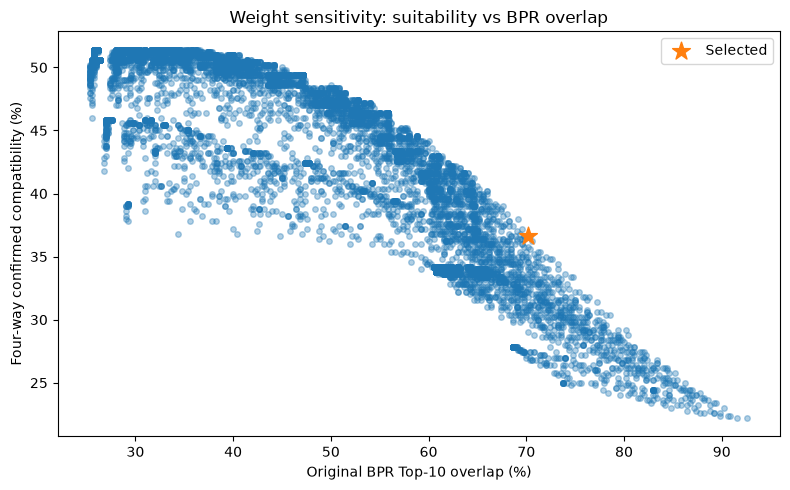

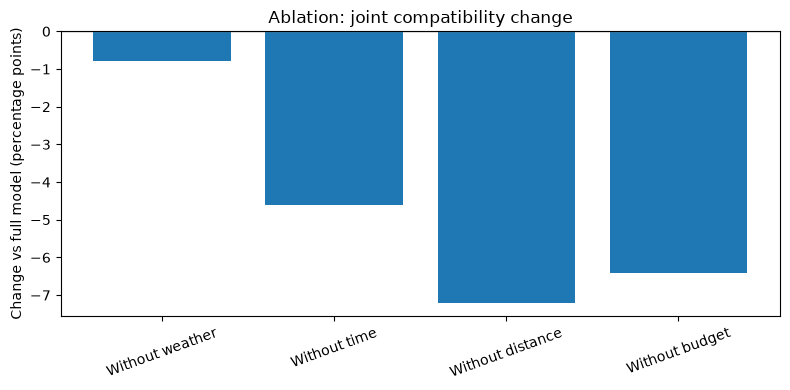

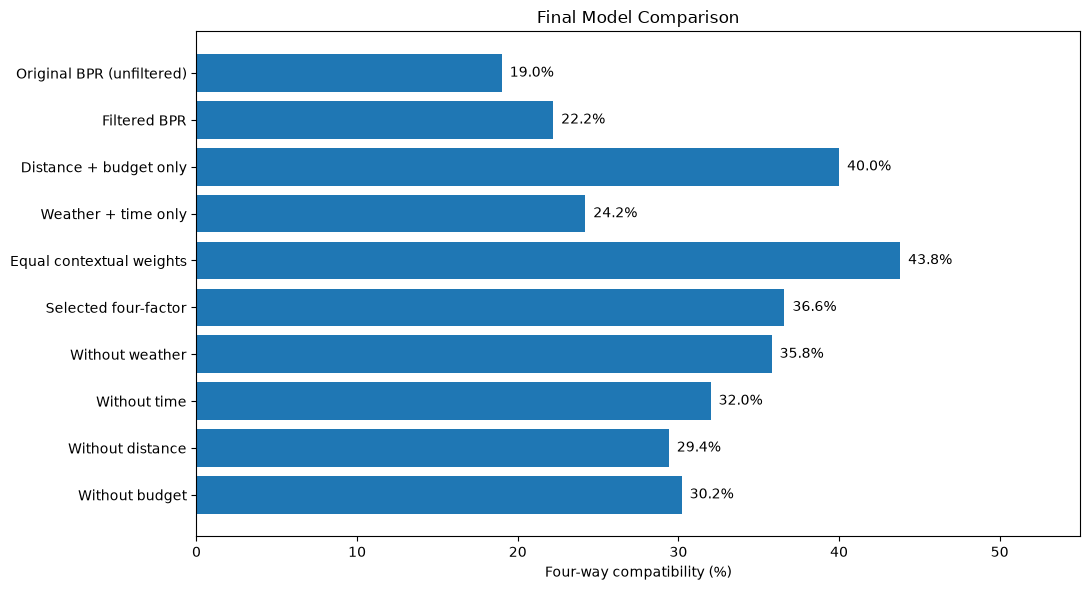

Saved results to: /Users/stacey/Downloads/Egocentric-Activity-Recommendation-System/data/processed/combined_contextual_evaluation


In [ ]:
out_dir=processed/'combined_contextual_evaluation'
out_dir.mkdir(parents=True,exist_ok=True)

sensitivity.to_csv(out_dir/'weight_sensitivity.csv',
    index=False)

ablations.to_csv(out_dir/'ablation_results.csv',
    index=False)

comparison.to_csv(out_dir/'final_comparison.csv',
    index=False)

selected_top10.to_csv(out_dir/'selected_top10.csv',
    index=False)

fig,ax=plt.subplots(figsize=(8,5))

ax.scatter(100*sensitivity['bpr_overlap'],
    100*sensitivity['joint_compatibility'],
    alpha=.35,s=16)

ax.scatter([100*selected['bpr_overlap']],
    [100*selected['joint_compatibility']],
    marker='*',
    s=180,
    label='Selected')

ax.set(xlabel='Original BPR Top-10 overlap (%)',
       ylabel='Four-way confirmed compatibility (%)',
       title='Weight sensitivity: suitability vs BPR overlap')

ax.legend();fig.tight_layout();fig.savefig(out_dir/'weight_tradeoff.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(8,4))
subset=ablations[ablations.configuration.ne('Full model')]

ax.bar(subset['configuration'],
    subset['joint_delta_vs_full_pp'])

ax.axhline(0,color='gray',
    linewidth=1)

ax.set(ylabel='Change vs full model (percentage points)',
    title='Ablation: joint compatibility change')

ax.tick_params(axis='x',rotation=20)
fig.tight_layout();fig.savefig(out_dir/'ablation.png',dpi=160);plt.show()

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    comparison["configuration"],
    comparison["joint_compatibility"] * 100
)

ax.invert_yaxis()
ax.set_xlabel("Four-way compatibility (%)")
ax.set_title("Final Model Comparison")

for i, value in enumerate(comparison["joint_compatibility"] * 100):
    ax.text(value + 0.5, i, f"{value:.1f}%", va="center")

ax.set_xlim(0, 55)
plt.tight_layout()
plt.show()

print('Saved results to:',out_dir)

In [29]:
print("Final selected weights:")
for factor, weight in zip(COMPONENTS, selected_weights):
    print(f"{factor}: {weight:.2f} ({weight:.0%})")

Final selected weights:
bpr: 0.45 (45%)
weather: 0.05 (5%)
time: 0.35 (35%)
distance: 0.10 (10%)
budget: 0.05 (5%)


In [30]:
import numpy as np
import plotly.graph_objects as go

plot_df = sensitivity.copy()

# Selected configuration
selected_mask = np.isclose(
    plot_df[COMPONENTS].to_numpy(),
    np.asarray(selected_weights)
).all(axis=1)

selected_plot = plot_df.loc[selected_mask]

# Configurations meeting overlap requirement
eligible = plot_df[plot_df["bpr_overlap"] >= 0.70]

fig = go.Figure()

# All configurations
fig.add_trace(go.Scatter3d(
    x=plot_df["bpr_overlap"] * 100,
    y=plot_df["joint_compatibility"] * 100,
    z=plot_df["bpr"],
    mode="markers",
    marker=dict(
        size=2,
        color=plot_df["bpr"],
        colorscale="Viridis",
        cmin=0,
        cmax=1,
        opacity=0.15,
        colorbar=dict(title="BPR Weight")
    ),
    name="All configurations"
))

# Configurations satisfying overlap threshold
fig.add_trace(go.Scatter3d(
    x=eligible["bpr_overlap"] * 100,
    y=eligible["joint_compatibility"] * 100,
    z=eligible["bpr"],
    mode="markers",
    marker=dict(
        size=3,
        color="teal",
        opacity=0.65
    ),
    name="Overlap >= 70%"
))

# Selected model
fig.add_trace(go.Scatter3d(
    x=selected_plot["bpr_overlap"] * 100,
    y=selected_plot["joint_compatibility"] * 100,
    z=selected_plot["bpr"],
    mode="markers",
    marker=dict(
        size=11,
        color="darkorange",
        symbol="diamond"
    ),
    name="Selected model"
))

# 70% BPR overlap reference plane
y_min = plot_df["joint_compatibility"].min() * 100
y_max = plot_df["joint_compatibility"].max() * 100

fig.add_trace(go.Surface(
    x=[[70, 70], [70, 70]],
    y=[[y_min, y_max], [y_min, y_max]],
    z=[[0, 0], [1, 1]],
    surfacecolor=[[1, 1], [1, 1]],
    colorscale=[[0, "lightgray"], [1, "lightgray"]],
    opacity=0.15,
    showscale=False,
    name="70% overlap threshold",
    hoverinfo="skip"
))

fig.update_layout(
    title="Weight Sensitivity: Personalization vs Context",
    template="plotly_white",
    scene=dict(
        xaxis_title="BPR Overlap (%)",
        yaxis_title="Contextual Compatibility (%)",
        zaxis_title="BPR Weight",
        aspectmode="manual",
        aspectratio=dict(x=1.4, y=1.2, z=0.55),
        camera=dict(
            eye=dict(x=1.7, y=1.6, z=1.0),
            projection=dict(type="orthographic")
        )
    ),
    width=1100,
    height=700,
    legend=dict(x=0.02, y=0.98)
)

fig.show(renderer="browser")

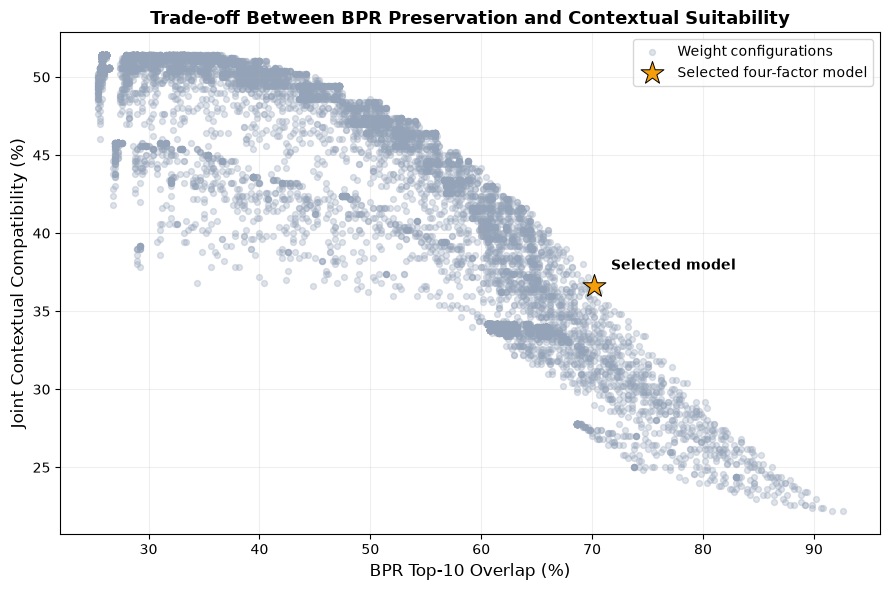

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# All evaluated weight combinations
x = sensitivity["bpr_overlap"] * 100
y = sensitivity["joint_compatibility"] * 100

# Find your selected model
selected_mask = np.isclose(
    sensitivity[COMPONENTS].to_numpy(),
    np.asarray(selected_weights)
).all(axis=1)

selected_plot = sensitivity.loc[selected_mask]

fig, ax = plt.subplots(figsize=(9, 6))

# All configurations
ax.scatter(
    x, y,
    color="#94A3B8",
    alpha=0.3,
    s=18,
    label="Weight configurations"
)

# Selected model
ax.scatter(
    selected_plot["bpr_overlap"] * 100,
    selected_plot["joint_compatibility"] * 100,
    color="#F59E0B",
    marker="*",
    s=300,
    edgecolor="black",
    linewidth=0.7,
    label="Selected four-factor model",
    zorder=5
)

# Label selected model
for _, row in selected_plot.iterrows():
    ax.annotate(
        "Selected model",
        (
            row["bpr_overlap"] * 100,
            row["joint_compatibility"] * 100
        ),
        xytext=(12, 12),
        textcoords="offset points",
        fontsize=10,
        weight="bold"
    )

ax.set_xlabel("BPR Top-10 Overlap (%)", fontsize=12)
ax.set_ylabel("Joint Contextual Compatibility (%)", fontsize=12)

ax.set_title(
    "Trade-off Between BPR Preservation and Contextual Suitability",
    fontsize=13,
    weight="bold"
)

ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()

plt.savefig(
    "bpr_context_tradeoff.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

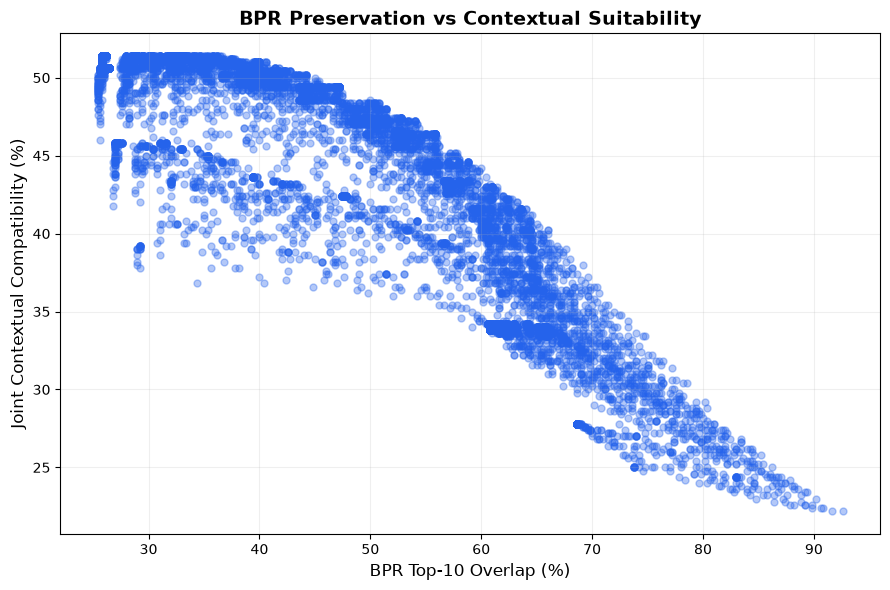

In [32]:
import matplotlib.pyplot as plt

plot_df = sensitivity.copy()

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    plot_df["bpr_overlap"] * 100,
    plot_df["joint_compatibility"] * 100,
    color="#2563EB",
    alpha=0.35,
    s=25
)

ax.set_xlabel("BPR Top-10 Overlap (%)", fontsize=12)
ax.set_ylabel("Joint Contextual Compatibility (%)", fontsize=12)

ax.set_title(
    "BPR Preservation vs Contextual Suitability",
    fontsize=14,
    fontweight="bold"
)

ax.grid(alpha=0.2)
plt.tight_layout()

plt.show()


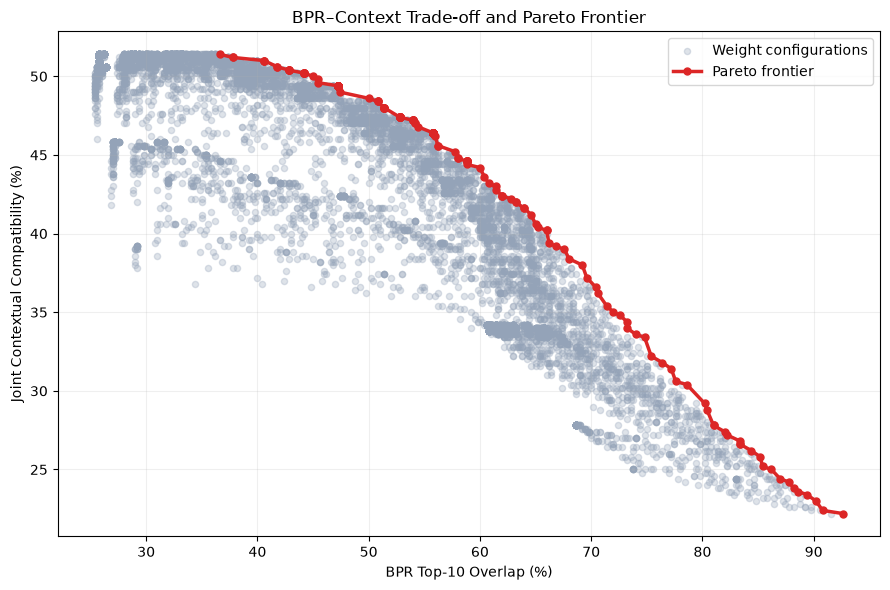

In [33]:
import numpy as np
import matplotlib.pyplot as plt

plot_df = sensitivity.copy()

points = plot_df[
    ["bpr_overlap", "joint_compatibility"]
].dropna().to_numpy()

# Find non-dominated configurations
pareto = np.ones(len(points), dtype=bool)

for i, (x, y) in enumerate(points):
    dominated = (
        (points[:, 0] >= x) &
        (points[:, 1] >= y) &
        (
            (points[:, 0] > x) |
            (points[:, 1] > y)
        )
    )
    pareto[i] = not dominated.any()

frontier = points[pareto]
frontier = frontier[np.argsort(frontier[:, 0])]

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    points[:, 0] * 100,
    points[:, 1] * 100,
    color="#94A3B8",
    alpha=0.3,
    s=20,
    label="Weight configurations"
)

ax.plot(
    frontier[:, 0] * 100,
    frontier[:, 1] * 100,
    color="#DC2626",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Pareto frontier"
)

ax.set_xlabel("BPR Top-10 Overlap (%)")
ax.set_ylabel("Joint Contextual Compatibility (%)")
ax.set_title("BPR–Context Trade-off and Pareto Frontier")

ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()

plt.show()


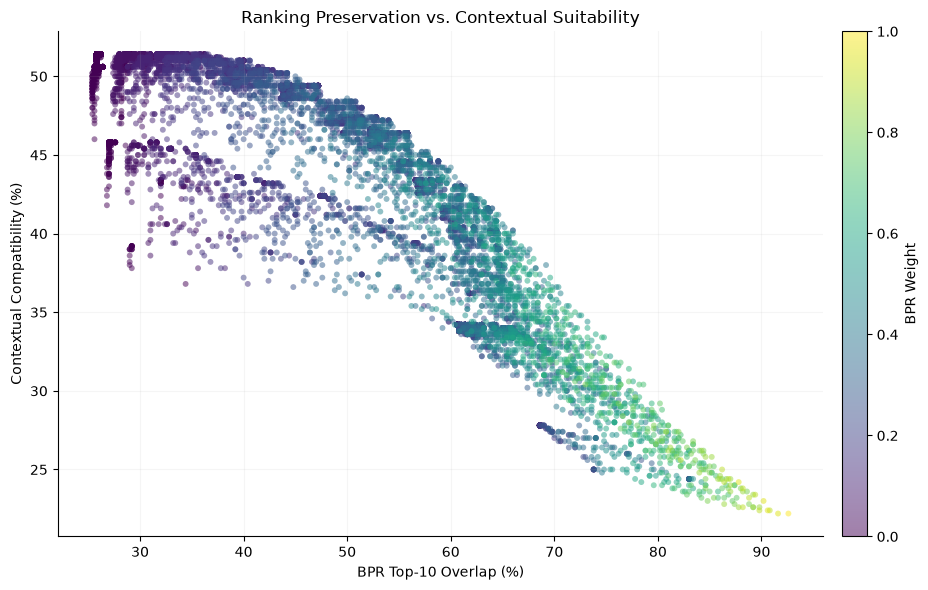

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = sensitivity.dropna(
    subset=["bpr_overlap", "joint_compatibility", "bpr"]
).copy()

fig, ax = plt.subplots(figsize=(10, 6))

sc = ax.scatter(
    plot_df["bpr_overlap"] * 100,
    plot_df["joint_compatibility"] * 100,
    c=plot_df["bpr"],
    cmap="viridis",
    s=18,
    alpha=0.5,
    linewidths=0,
    rasterized=True
)

ax.set(
    xlabel="BPR Top-10 Overlap (%)",
    ylabel="Contextual Compatibility (%)",
    title="Ranking Preservation vs. Contextual Suitability"
)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.12)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("BPR Weight")

fig.tight_layout()
fig.savefig(
    "tradeoff_slide.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
